# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aurea McIntosh, Evie McMahan, Zoe Edelblum

**Date:** 11/16/2026

In [9]:
# Your Phase 1 solution to the problem goes here.


# Question 1: Check out the data set `heart_failure` and appropriately clean it.

In [10]:
import pandas as pd

# check and clean the dataset
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')

print("Shape before cleaning:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nSummary stats:\n", df.describe().T[['min', 'mean', 'max']])

# clean the dataset:
# drop any missing values or duplicate rows
df_clean = df.dropna().drop_duplicates().copy()

# fix fractional ages (two rows have 60.667) by rounding to whole integers
df_clean['age'] = df_clean['age'].round().astype(int)

print("\nShape after cleaning:", df_clean.shape)

Shape before cleaning: (299, 13)
Missing values:
 age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Duplicate rows: 0

Summary stats:
                               min           mean       max
age                          40.0      60.833893      95.0
anaemia                       0.0       0.431438       1.0
creatinine_phosphokinase     23.0     581.839465    7861.0
diabetes                      0.0       0.418060       1.0
ejection_fraction            14.0      38.083612      80.0
high_blood_pressure           0.0       0.351171       1.0
platelets                 25100.0  263358.029264  850000.0
serum_creatinine              0.5       

The heart_failure dataset was inspected (299 rows, 13 columns) for missing values, duplicate rows, invalid ranges, and data types. There are 0 missing values and 0 duplicate rows, and all clinical measurements fall within realistic ranges (no negative values or impossible outliers). However, age is stored as a decimal (float64) with two rows listed as 60.667, so age was rounded to whole integers (int) and .dropna().drop_duplicates() was ran to create df_clean. All columns are numeric, so no categorical encoding is needed

# Question 2: Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.

Decision Tree Test Accuracy: 0.6833
Decision Tree Confusion Matrix:
 [[28  7]
 [12 13]]

Logistic Regression Test Accuracy: 0.8000
Logistic Regression Confusion Matrix:
 [[34  1]
 [11 14]]


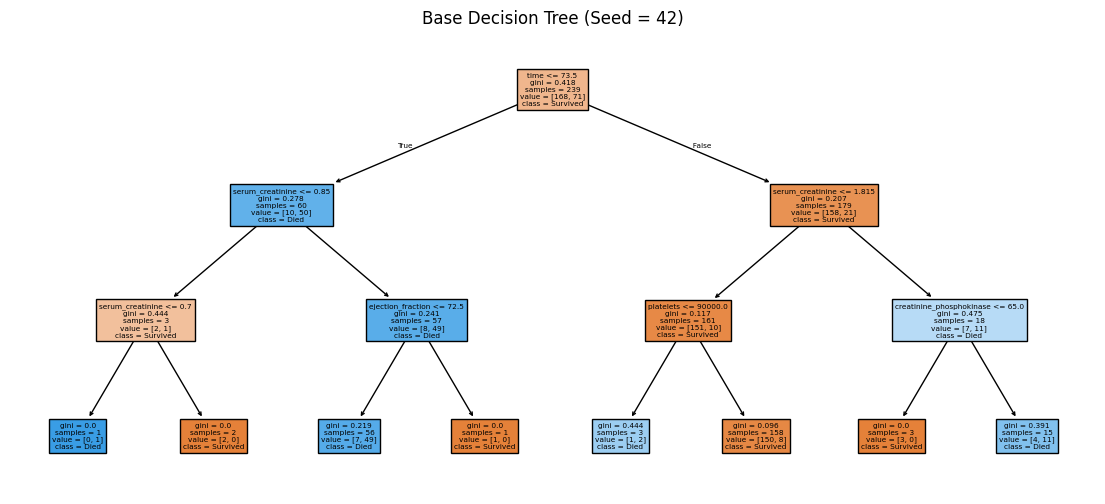


Base Logistic Regression Coefficients:
age                         0.6617
anaemia                    -0.0517
creatinine_phosphokinase    0.1106
diabetes                    0.1641
ejection_fraction          -0.8763
high_blood_pressure        -0.0608
platelets                  -0.1704
serum_creatinine            0.7019
serum_sodium               -0.2605
sex                        -0.3627
smoking                     0.0714
time                       -1.6522
dtype: float64


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import pandas as pd

# separate features (X) and target (y)
X = df_clean.drop('DEATH_EVENT', axis=1)
y = df_clean['DEATH_EVENT']

# performed train test split for a specific seed (save the seed for reproducibility)
seed_base = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed_base
)

# scale features so logistic regression is clean
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# fit a tree and a linear (logistic) model on the training data
tree_base = DecisionTreeClassifier(max_depth=3, random_state=seed_base)
tree_base.fit(X_train, y_train)

log_base = LogisticRegression(max_iter=1000)
log_base.fit(X_train_scaled, y_train)

# evaluated performance on the test data
tree_test_classes = tree_base.predict(X_test)
log_test_classes = log_base.predict(X_test_scaled)

print(f"Decision Tree Test Accuracy: {accuracy_score(y_test, tree_test_classes):.4f}")
print("Decision Tree Confusion Matrix:\n", confusion_matrix(y_test, tree_test_classes))

print(f"\nLogistic Regression Test Accuracy: {accuracy_score(y_test, log_test_classes):.4f}")
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, log_test_classes))

# set aside the predictions the models make
pred_tree_base = tree_base.predict_proba(X_test)[:, 1]
pred_log_base = log_base.predict_proba(X_test_scaled)[:, 1]

# inspect the base tree and logistic coefficients
plt.figure(figsize=(14, 6))
plot_tree(tree_base, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True)
plt.title(f"Base Decision Tree (Seed = {seed_base})")
plt.show()

print("\nBase Logistic Regression Coefficients:")
print(pd.Series(log_base.coef_[0], index=X.columns).round(4))

# Question 3: Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients? Set aside the predictions these models make.

In [12]:
# Seed 1
seed_1 = 1
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(X, y, test_size=0.2, random_state=seed_1)
scaler_1 = StandardScaler()
X_train_1_sc = scaler_1.fit_transform(X_train_1)

tree_1 = DecisionTreeClassifier(max_depth=3, random_state=seed_1)
tree_1.fit(X_train_1, y_train_1)

log_1 = LogisticRegression(max_iter=1000)
log_1.fit(X_train_1_sc, y_train_1)

# Set aside predictions on the base test set (X_test)
pred_tree_1 = tree_1.predict_proba(X_test)[:, 1]
pred_log_1 = log_1.predict_proba(scaler_1.transform(X_test))[:, 1]

# Seed 10
seed_10 = 10
X_train_10, X_test_10, y_train_10, y_test_10 = train_test_split(X, y, test_size=0.2, random_state=seed_10)
scaler_10 = StandardScaler()
X_train_10_sc = scaler_10.fit_transform(X_train_10)

tree_10 = DecisionTreeClassifier(max_depth=3, random_state=seed_10)
tree_10.fit(X_train_10, y_train_10)

log_10 = LogisticRegression(max_iter=1000)
log_10.fit(X_train_10_sc, y_train_10)

# Set aside predictions on the base test set (X_test)
pred_tree_10 = tree_10.predict_proba(X_test)[:, 1]
pred_log_10 = log_10.predict_proba(scaler_10.transform(X_test))[:, 1]

# Seed 99
seed_99 = 99
X_train_99, X_test_99, y_train_99, y_test_99 = train_test_split(X, y, test_size=0.2, random_state=seed_99)
scaler_99 = StandardScaler()
X_train_99_sc = scaler_99.fit_transform(X_train_99)

tree_99 = DecisionTreeClassifier(max_depth=3, random_state=seed_99)
tree_99.fit(X_train_99, y_train_99)

log_99 = LogisticRegression(max_iter=1000)
log_99.fit(X_train_99_sc, y_train_99)

# Set aside predictions on the base test set (X_test)
pred_tree_99 = tree_99.predict_proba(X_test)[:, 1]
pred_log_99 = log_99.predict_proba(scaler_99.transform(X_test))[:, 1]

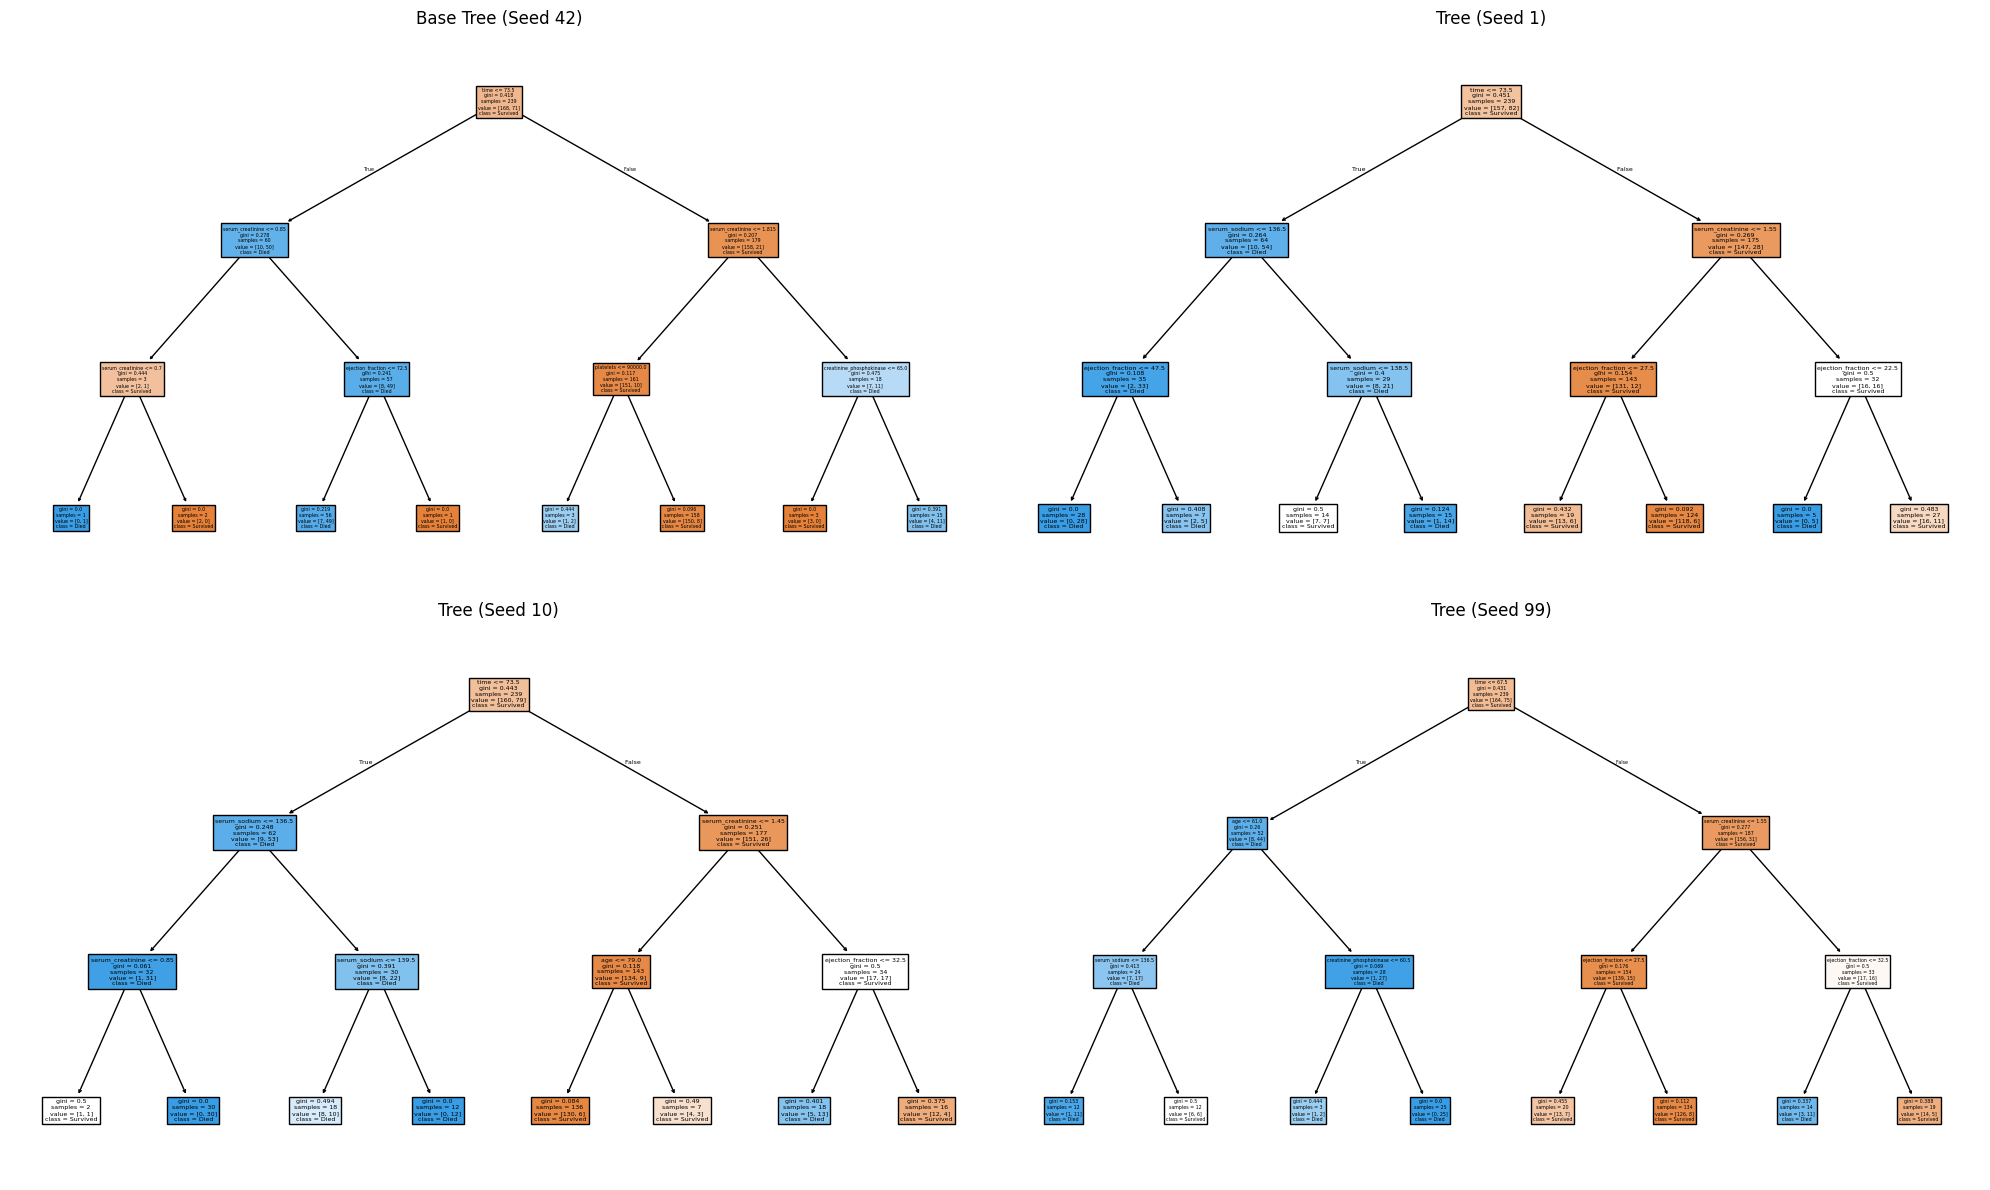

Logistic Regression Coefficients Across Seeds:
                          Base (42)  Seed 1  Seed 10  Seed 99
age                          0.6617  0.4269   0.5817   0.5564
anaemia                     -0.0517 -0.0292   0.1533  -0.0983
creatinine_phosphokinase     0.1106  0.2224   0.2050   0.1592
diabetes                     0.1641  0.1789   0.1621   0.0664
ejection_fraction           -0.8763 -0.7915  -0.9757  -0.9018
high_blood_pressure         -0.0608 -0.1224  -0.0709   0.0369
platelets                   -0.1704 -0.2394  -0.1799  -0.1948
serum_creatinine             0.7019  0.7312   1.1086   0.7202
serum_sodium                -0.2605 -0.2819  -0.2972  -0.2704
sex                         -0.3627 -0.1796  -0.1755  -0.2159
smoking                      0.0714 -0.0431  -0.0657   0.0664
time                        -1.6522 -1.4788  -1.6339  -1.3374


In [13]:
# Plot all 4 trees in a 2x2 grid so it can be compared
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

plot_tree(tree_base, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True, ax=axes[0, 0])
axes[0, 0].set_title("Base Tree (Seed 42)")

plot_tree(tree_1, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True, ax=axes[0, 1])
axes[0, 1].set_title("Tree (Seed 1)")

plot_tree(tree_10, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True, ax=axes[1, 0])
axes[1, 0].set_title("Tree (Seed 10)")

plot_tree(tree_99, feature_names=X.columns, class_names=['Survived', 'Died'], filled=True, ax=axes[1, 1])
axes[1, 1].set_title("Tree (Seed 99)")

plt.tight_layout()
plt.show()

# Compare Logistic Regression coefficients side by side
coef_table = pd.DataFrame({
    'Base (42)': log_base.coef_[0],
    'Seed 1': log_1.coef_[0],
    'Seed 10': log_10.coef_[0],
    'Seed 99': log_99.coef_[0]
}, index=X.columns)

print("Logistic Regression Coefficients Across Seeds:")
print(coef_table.round(4))

**How Different are the Decision Trees?**

Across the different random train-test splits, the decision trees change quite a bit, especially once you look past the very top split. All four trees start by splitting on time at the top, though even that cutoff changes slightly and stays at time <= 73.50 for seeds 42, 1, and 10, and dropping to time <= 67.50 for seed 99. Once you go down to the second and third levels, the trees pick completely different variables and cutoff numbers. For example, on the left side (time <= 73.50), the base tree (seed=42) splits on serum_creatinine and ejection_fraction, while seeds 1 and 10 both switch to serum_sodium, and seed 99 switches to age. The same thing happens on the right side (time > 73.50), where the bottom splits bounce between platelets, creatinine_phosphokinase, ejection_fraction, and age depending on the seed. Because a decision tree builds branches one step at a time, changing a small portion of the training data can cause the tops to shift, which then changes all the branches underneath.

**How Different Are the Linear Model Coefficients?**

While the decision tree models are inconsistent on each of the four random splits, the coefficients of the logistic regression model remain constant through all four splits. The coefficients of the most influential features always have the exact same signs and nearly identical values in each split: time has coefficients between -1.34 and -1.65, ejection_fraction has coefficients between -0.79 and -0.98, serum_creatinine has coefficients between 0.70 and 1.11, age has coefficients between 0.43 and 0.66, and serum_sodium has coefficients between -0.26 and -0.30. Only the coefficients of binary features with small values such as anaemia, high_blood_pressure, and smoking change their signs in different splits. Unlike the decision tree model, the logistic regression model uses all the training samples for fitting the final curve.

# Question 4

# Question 5

# Question 6

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [14]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]